# Fiche 3 — Ce que dit une ACP… et ce qu'elle ne dit pas

| | |
|---|---|
| 🎯 **Objectif** | Lancer une ACP sur des variables standardisées, lire l'éboulis des valeurs propres et savoir quand ne pas interpréter les axes |
| ⏱️ **Durée** | 45 min |
| 🧰 **Prérequis** | Moyenne, écart-type, corrélation |
| 🔗 **Dans le projet** | Étape 1 (ACP demandée sur le jeu Agriculture Crop Yield) |

> **L'idée clé.** L'ACP cherche des **directions** qui résument plusieurs variables corrélées. Si les variables ne sont pas corrélées, il n'y a rien à résumer : les valeurs propres sont toutes égales, et c'est une information, pas un échec. L'ACP ne regarde jamais la cible : elle ne dit pas ce qui *prédit* le rendement.

## 1. Un cas où l'ACP résume bien : des variables liées

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from agrireco import io, viz

viz.apply_style()
rng = np.random.default_rng(0)
taille = rng.normal(170, 10, 500)
exemple = pd.DataFrame({
    "taille_cm": taille,
    "poids_kg": 0.9 * taille - 85 + rng.normal(0, 6, 500),       # lié à la taille
    "pointure": 0.25 * taille - 2 + rng.normal(0, 1.2, 500),     # lié à la taille
})
acp = PCA().fit(StandardScaler().fit_transform(exemple))
print("valeurs propres :", acp.explained_variance_.round(2))
print("part de variance :", acp.explained_variance_ratio_.round(2))

valeurs propres : [2.69 0.24 0.08]
part de variance : [0.89 0.08 0.03]


L'**éboulis** est le graphique des valeurs propres, de la plus grande à la plus petite. Ici : trois variables, mais
**une seule direction** porte l'essentiel (la « corpulence ») : la première valeur propre est
bien au-dessus de 1, les autres bien en dessous. On pourrait résumer ces trois colonnes par une seule.

> Une **valeur propre** mesure la variance portée par une composante, en unités de « variables standardisées » :
> 1 = autant qu'une variable seule. Au-dessus de 1, la composante résume plusieurs variables.

## 2. Le jeu Agriculture Crop Yield

In [2]:
agri_dir, _ = io.download()
agri = pd.read_csv(agri_dir / "crop_yield.csv")
variables = ["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest", "Fertilizer_Used", "Irrigation_Used"]
X = StandardScaler().fit_transform(agri[variables].astype(float))
acp = PCA().fit(X)
print("valeurs propres :", acp.explained_variance_.round(3))

valeurs propres : [1.003 1.003 1.001 0.997 0.997]


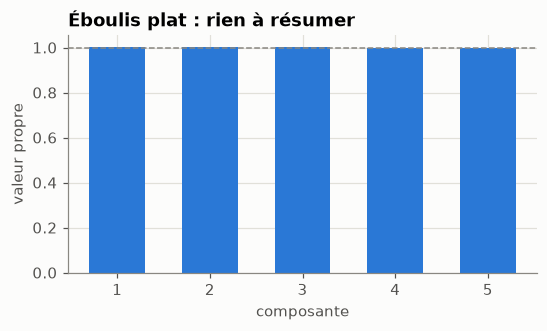

In [3]:
fig, ax = plt.subplots(figsize=(5.5, 2.8))
ax.bar(range(1, 6), acp.explained_variance_, color=viz.BLUE, width=0.6)
ax.axhline(1, color=viz.MUTED, ls="--", lw=1)
ax.set_xlabel("composante")
ax.set_ylabel("valeur propre")
ax.set_title("Éboulis plat : rien à résumer")
plt.show()

Les 5 valeurs propres valent **environ 1** : chaque composante porte la même part d'information qu'une variable
seule. Les variables sont **non corrélées** ; aucune réduction de dimension n'est possible.

## ⚠️ Piège n° 1 : lire les axes quand les valeurs propres sont égales
Quand les valeurs propres sont égales, n'importe quelle rotation des axes conviendrait aussi bien. Démonstration :
on refait l'ACP sur deux moitiés du jeu et on compare la première composante.

In [4]:
moitie = len(X) // 2
cp1_a = PCA().fit(X[:moitie]).components_[0]
cp1_b = PCA().fit(X[moitie:]).components_[0]
cp1_b = cp1_b * np.sign(cp1_a @ cp1_b)  # le signe d'un axe est arbitraire : on aligne les deux avant de comparer
print(pd.DataFrame({"CP1 moitié A": cp1_a, "CP1 moitié B": cp1_b}, index=variables).round(2))

                     CP1 moitié A  CP1 moitié B
Rainfall_mm                  0.07          0.26
Temperature_Celsius          0.54          0.52
Days_to_Harvest             -0.32         -0.67
Fertilizer_Used              0.58          0.46
Irrigation_Used              0.52          0.02


Même en alignant les signes (le signe d'un axe est toujours arbitraire, ce n'est pas un problème), la « première
composante » change complètement d'une moitié à l'autre : l'irrigation, la pluie et la durée jusqu'à la récolte n'y
ont plus du tout le même poids. Elle n'a **aucun sens stable**. Interpréter
son cercle des corrélations (« CP1 = l'axe de l'irrigation ») reviendrait à commenter du bruit.

## ⚠️ Piège n° 2 : oublier de standardiser

In [5]:
brut = PCA().fit(agri[variables].astype(float))
print("valeurs propres sans standardiser :", brut.explained_variance_.round(2))
print("part de variance de CP1 :", round(brut.explained_variance_ratio_[0], 3))

valeurs propres sans standardiser : [6.752271e+04 6.735700e+02 5.214000e+01 2.500000e-01 2.500000e-01]
part de variance de CP1 : 0.989


Sans standardisation, la pluie (en mm, variance de l'ordre de 67 000) écrase tout : CP1 « explique » presque
100 % de la variance… parce qu'elle **est** la pluie. Ce n'est pas une structure, c'est une question d'unités.

### ✍️ À toi de jouer

L'ACP ne regarde pas la cible. Pour savoir quelles variables comptent pour le rendement, ajuste une régression linéaire (`sklearn.linear_model.LinearRegression`) du rendement sur les 5 variables, affiche les coefficients **bruts**, puis l'**effet d'un écart-type** de chaque variable (coefficient × écart-type). Lesquels dominent ?

In [6]:
# Ta réponse ici

<details>
<summary><b>💡 Voir une solution</b> (après avoir cherché !)</summary>

```python
from sklearn.linear_model import LinearRegression

reg = LinearRegression().fit(agri[variables].astype(float), agri["Yield_tons_per_hectare"])
print(pd.Series(reg.coef_, index=variables).round(4))
print("R² :", round(reg.score(agri[variables].astype(float), agri["Yield_tons_per_hectare"]), 3))
print((pd.Series(reg.coef_, index=variables) * agri[variables].astype(float).std()).round(2))
```

**Pourquoi ?** un coefficient brut dépend de l'unité : 0,005 t/ha **par mm** paraît minuscule, mais la pluie varie de 900 mm, soit environ 4,5 t/ha. Rapportée à un écart-type, la pluie (≈ 1,3 t/ha) pèse plus que l'engrais (≈ 0,75) et l'irrigation (≈ 0,6) — c'est le même piège des unités que pour l'ACP. Pour une variable 0/1, l'écart-type dépend de la proportion (ici 50/50) : on lit aussi l'effet brut (+1,5 t/ha). Une ACP plate et une régression très nette ne se contredisent pas : elles répondent à deux questions différentes (« mes variables sont-elles redondantes ? » contre « qu'est-ce qui fait varier la cible ? »). Attention : ce jeu est simulé, ces coefficients sont les règles de la simulation.
</details>

## ✅ À retenir

1. On standardise avant l'ACP (sinon la variable aux plus grandes unités gagne).
2. Éboulis : valeurs propres > 1 = composantes qui résument plusieurs variables ; toutes ≈ 1 = rien à résumer.
3. Valeurs propres égales → axes arbitraires : on ne lit ni les axes ni le cercle des corrélations.
4. L'ACP ne regarde pas la cible : pour les variables qui prédisent, on utilise un modèle.
5. Une ACP « vide » est une conclusion valable, à écrire telle quelle.